Los repositorios y datasets oficiales para empezar a experimentar son:Para Grafos y Comunidades:TwiBot-22 / TwiBot-20: Archivo del repositorio en GitHub (BunsenFeng/TwiBot-20) y ficha técnica en Botometer Repository.Cresci-2017: Disponible en Kaggle (hashemalsalmi/cresci-2017) y el subset de pruebas en GitHub (ashu273k/TrustNet).  Para Texto y Similitud Semántica:MGTBench: Disponible en GitHub (MBZUAI-NLP/MGTBench).

In [2]:
!pip install pyvis pandas sentence-transformers scikit-learn seaborn matplotlib fastapi uvicorn community python-louvain kagglehub

In [3]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

# PyVis (importación corregida para evitar NameError)
from pyvis.network import Network

# Procesamiento de lenguaje natural y similitud
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Detección de comunidades y anomalías
from community import community_louvain
from sklearn.ensemble import IsolationForest

# API
import fastapi
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

/home/adalisa/Documentos/proyectos_git/proyecto_botnet/venv_bot/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
import re
import pandas as pd
import numpy as np
import networkx as nx
from pyvis.network import Network
from community import community_louvain
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import IsolationForest
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import List, Optional

import os
import glob
import pandas as pd
import kagglehub

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

In [ ]:
# 1. Descargar la última versión del dataset
path = kagglehub.dataset_download("mmmarchetti/tweets-dataset")
print("Ruta de descarga de los archivos:", path)

# 2. Localizar el archivo CSV dentro de la carpeta descargada
csv_files = glob.glob(os.path.join(path, "*.csv"))

if csv_files:
    # Cargar el primer archivo CSV encontrado
    dataset_path = csv_files[0]
    df = pd.read_csv(dataset_path)
    print(f"\nDataset cargado exitosamente desde: {dataset_path}")
    print(f"Dimensiones del DataFrame: {df.shape}")
    
    # Vista previa de las primeras filas
    display(df.head())
else:
    print("No se encontraron archivos CSV en la ruta especificada.")

Ruta de descarga de los archivos: /home/adalisa/.cache/kagglehub/datasets/mmmarchetti/tweets-dataset/versions/1

Dataset cargado exitosamente desde: /home/adalisa/.cache/kagglehub/datasets/mmmarchetti/tweets-dataset/versions/1/tweets.csv
Dimensiones del DataFrame: (52542, 10)


,author,content,country,date_time,id,language,latitude,longitude,number_of_likes,number_of_shares
0,katyperry,Is history repeating itself...?#DONTNORMALIZEH...,NaN,12/01/2017 19:52,8.196330e+17,en,NaN,NaN,7900,3472
1,katyperry,@barackobama Thank you for your incredible gra...,NaN,11/01/2017 08:38,8.191010e+17,en,NaN,NaN,3689,1380
2,katyperry,Life goals. https://t.co/XIn1qKMKQl,NaN,11/01/2017 02:52,8.190140e+17,en,NaN,NaN,10341,2387
3,katyperry,Me right now 🙏🏻 https://t.co/gW55C1wrwd,NaN,11/01/2017 02:44,8.190120e+17,en,NaN,NaN,10774,2458
4,katyperry,SISTERS ARE DOIN' IT FOR THEMSELVES! 🙌🏻💪🏻❤️ ht...,NaN,10/01/2017 05:22,8.186890e+17,en,NaN,NaN,17620,4655


In [11]:

df = df.rename(columns={
    'author': 'user_id',
    'content': 'text',
    'date_time': 'created_at'
})

def extract_mention(text):
    if pd.isna(text):
        return None
    mentions = re.findall(r'@(\w+)', str(text))
    return mentions[0] if mentions else None

df['mentioned_user'] = df['text'].apply(extract_mention)
df['created_at'] = pd.to_datetime(df['created_at'], format='%d/%m/%Y %H:%M', errors='coerce')
df = df.dropna(subset=['created_at', 'text', 'user_id'])
df['timestamp'] = df['created_at'].astype('int64') // 10**9

G = nx.Graph()
for _, row in df.iterrows():
    u_src = str(row['user_id'])
    u_dst = str(row['mentioned_user']) if pd.notna(row['mentioned_user']) else None
    G.add_node(u_src)
    if u_dst and u_dst != 'None' and u_dst != u_src:
        G.add_edge(u_src, u_dst)

partition = community_louvain.best_partition(G)

model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
text_embeddings = model.encode(df['text'].tolist(), show_progress_bar=False, batch_size=256)
df['embedding'] = list(text_embeddings)

user_embeddings = {}
user_timestamps = {}
for user, group in df.groupby('user_id'):
    u_str = str(user)
    user_embeddings[u_str] = np.mean(np.array(group['embedding'].tolist()), axis=0)
    user_timestamps[u_str] = group['timestamp'].sort_values().tolist()

embedding_dim = text_embeddings.shape[1]
all_users = list(partition.keys())
for u in all_users:
    if u not in user_embeddings:
        user_embeddings[u] = np.zeros(embedding_dim)
        user_timestamps[u] = []

user_matrix = np.array([user_embeddings[u] for u in all_users])
user_to_idx = {user: idx for idx, user in enumerate(all_users)}
sim_matrix = cosine_similarity(user_matrix)

features_list = []
community_metadata = []

for comm_id in set(partition.values()):
    users_in_comm = [user for user, c in partition.items() if c == comm_id]
    if len(users_in_comm) > 1:
        indices = [user_to_idx[u] for u in users_in_comm]
        sub_matrix = sim_matrix[np.ix_(indices, indices)]
        mask = ~np.eye(sub_matrix.shape[0], dtype=bool)
        avg_sim = float(sub_matrix[mask].mean()) if mask.any() else 0.0

        sub_graph = G.subgraph(users_in_comm)
        density = float(nx.density(sub_graph))

        comm_iat_std = []
        for u in users_in_comm:
            ts = user_timestamps[u]
            if len(ts) > 1:
                iats = np.diff(ts)
                comm_iat_std.append(np.std(iats))
            else:
                comm_iat_std.append(300.0)
        avg_iat_std = float(np.mean(comm_iat_std))

        features_list.append([density, avg_sim, avg_iat_std])
        community_metadata.append({
            'comm_id': comm_id,
            'users': users_in_comm,
            'density': density,
            'avg_sim': avg_sim,
            'avg_iat_std': avg_iat_std
        })

X_real = np.array(features_list)

baseline_human_data = np.array([
    [0.10, 0.01, 250.0],
    [0.15, -0.02, 180.0],
    [0.08, 0.05, 320.0],
    [0.20, 0.00, 150.0]
])
X_train = np.vstack([baseline_human_data, X_real])

iso_forest = IsolationForest(contamination=0.15, random_state=42)
iso_forest.fit(X_train)

preds = iso_forest.predict(X_real)
anomaly_scores = iso_forest.decision_function(X_real)

comm_status = {}
report_rows = []

for idx, meta in enumerate(community_metadata):
    c_id = meta['comm_id']
    density = meta['density']
    avg_sim = meta['avg_sim']
    avg_iat_std = meta['avg_iat_std']

    ml_is_bot = preds[idx] == -1
    raw_score = int(np.clip((0.5 - anomaly_scores[idx]) * 100, 0, 100))

    safeguard_triggered = (density >= 0.8 and avg_sim >= 0.8) or (avg_iat_std <= 1.0 and avg_sim >= 0.8)

    is_bot = (ml_is_bot and raw_score >= 60) or safeguard_triggered
    final_score = max(raw_score, 95) if safeguard_triggered else raw_score

    comm_status[c_id] = {
        'is_bot': is_bot,
        'score': final_score,
        'sim': round(avg_sim, 4),
        'density': round(density, 3),
        'iat_std': round(avg_iat_std, 2)
    }

    report_rows.append({
        'Comunidad': c_id,
        'Usuarios': len(meta['users']),
        'Densidad Grafo': round(density, 3),
        'Simil. Semántica': round(avg_sim, 4),
        'Varianza Temp. (s)': round(avg_iat_std, 2),
        'Risk Score ML': final_score,
        'Clasificación ML': 'BOTNET (Anomalía)' if is_bot else 'HUMANO (Normal)'
    })

report_df = pd.DataFrame(report_rows)
print(report_df.to_string(index=False))

net = Network(height='750px', width='100%', bgcolor='#222222', font_color='white', notebook=False)
net.barnes_hut(gravity=-8000, central_gravity=0.3, spring_length=100)

for node in G.nodes():
    c_id = partition[node]
    status = comm_status.get(c_id, {'is_bot': False, 'score': 0, 'density': 0, 'sim': 0, 'iat_std': 300})

    if status['is_bot']:
        color = '#ff4d4d'
        label_class = 'BOTNET (Anomalía)'
        size = 25
    else:
        color = '#4dda53'
        label_class = 'HUMANO (Normal)'
        size = 15

    hover_title = f"Usuario: {node}<br>Comunidad: {c_id}<br>Clasificación: {label_class}<br>Risk Score: {status['score']}/100"
    net.add_node(node, label=str(node), title=hover_title, color=color, size=size, shape='dot')

for src, dst in G.edges():
    net.add_edge(str(src), str(dst), color='#888888', width=1.5)

net.write_html("grafo_botnets_interactivo.html")

app = FastAPI(
    title="Botnet & Synthetic Content Detection API",
    description="Motor multi-capa de detección de bots mediante Grafos, Embeddings Semánticos y Telemetría Temporal.",
    version="1.0.0"
)

class PostData(BaseModel):
    user_id: str
    text: str
    created_at: str
    mentioned_user: Optional[str] = None

class DetectionRequest(BaseModel):
    posts: List[PostData]

@app.post("/analyze")
def analyze_network(payload: DetectionRequest):
    if len(payload.posts) < 2:
        raise HTTPException(status_code=400, detail="Se requieren al menos 2 publicaciones para construir el grafo de interacción.")

    data = [p.dict() for p in payload.posts]
    df_api = pd.DataFrame(data)
    df_api['timestamp'] = pd.to_datetime(df_api['created_at']).astype('int64') // 10**9

    G_api = nx.Graph()
    for _, row in df_api.iterrows():
        u_src = str(row['user_id'])
        u_dst = str(row['mentioned_user']) if pd.notna(row.get('mentioned_user')) else None
        G_api.add_node(u_src)
        if u_dst and u_dst != 'None' and u_dst != u_src:
            G_api.add_edge(u_src, u_dst)

    partition_api = community_louvain.best_partition(G_api)

    text_embeddings_api = model.encode(df_api['text'].tolist(), show_progress_bar=False)
    df_api['embedding'] = list(text_embeddings_api)

    user_embeddings_api = {}
    user_timestamps_api = {}
    for user, group in df_api.groupby('user_id'):
        u_str = str(user)
        user_embeddings_api[u_str] = np.mean(np.array(group['embedding'].tolist()), axis=0)
        user_timestamps_api[u_str] = group['timestamp'].sort_values().tolist()

    embedding_dim_api = text_embeddings_api.shape[1]
    all_users_api = list(partition_api.keys())
    for u in all_users_api:
        if u not in user_embeddings_api:
            user_embeddings_api[u] = np.zeros(embedding_dim_api)
            user_timestamps_api[u] = []

    user_matrix_api = np.array([user_embeddings_api[u] for u in all_users_api])
    user_to_idx_api = {user: idx for idx, user in enumerate(all_users_api)}
    sim_matrix_api = cosine_similarity(user_matrix_api)

    features_list_api = []
    community_metadata_api = []

    for comm_id in set(partition_api.values()):
        users_in_comm = [user for user, c in partition_api.items() if c == comm_id]
        indices = [user_to_idx_api[u] for u in users_in_comm]
        sub_matrix = sim_matrix_api[np.ix_(indices, indices)]
        mask = ~np.eye(sub_matrix.shape[0], dtype=bool)
        avg_sim = float(sub_matrix[mask].mean()) if mask.any() else 0.0

        sub_graph = G_api.subgraph(users_in_comm)
        density = float(nx.density(sub_graph))

        comm_iat_std = []
        for u in users_in_comm:
            ts = user_timestamps_api[u]
            if len(ts) > 1:
                iats = np.diff(ts)
                comm_iat_std.append(np.std(iats))
            else:
                comm_iat_std.append(300.0)
        avg_iat_std = float(np.mean(comm_iat_std))

        features_list_api.append([density, avg_sim, avg_iat_std])
        community_metadata_api.append({
            'comm_id': comm_id,
            'users': users_in_comm,
            'density': density,
            'avg_sim': avg_sim,
            'avg_iat_std': avg_iat_std
        })

    X_real_api = np.array(features_list_api)
    X_train_api = np.vstack([baseline_human_data, X_real_api])

    iso_forest_api = IsolationForest(contamination=0.15, random_state=42)
    iso_forest_api.fit(X_train_api)

    preds_api = iso_forest_api.predict(X_real_api)
    anomaly_scores_api = iso_forest_api.decision_function(X_real_api)

    results_api = []
    for idx, meta in enumerate(community_metadata_api):
        density = meta['density']
        avg_sim = meta['avg_sim']
        avg_iat_std = meta['avg_iat_std']

        ml_is_bot = preds_api[idx] == -1
        raw_score = int(np.clip((0.5 - anomaly_scores_api[idx]) * 100, 0, 100))

        safeguard_triggered = (density >= 0.8 and avg_sim >= 0.8) or (avg_iat_std <= 1.0 and avg_sim >= 0.8)

        is_bot = (ml_is_bot and raw_score >= 60) or safeguard_triggered
        final_score = max(raw_score, 95) if safeguard_triggered else raw_score

        results_api.append({
            "community_id": meta['comm_id'],
            "users_count": len(meta['users']),
            "users_list": meta['users'],
            "metrics": {
                "graph_density": round(density, 3),
                "semantic_similarity": round(avg_sim, 4),
                "time_variance_seconds": round(avg_iat_std, 2)
            },
            "risk_score": final_score,
            "classification": "BOTNET" if is_bot else "HUMAN"
        })

    return {
        "status": "success",
        "communities_analyzed": len(results_api),
        "results": results_api
    }

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2635.98it/s]


 Comunidad  Usuarios  Densidad Grafo  Simil. Semántica  Varianza Temp. (s)  Risk Score ML Clasificación ML
         0       719           0.003            0.0000              299.70             17  HUMANO (Normal)
         1       341           0.006            0.0000              299.56             18  HUMANO (Normal)
         2       115           0.018            0.0001              295.87             46  HUMANO (Normal)
         4       475           0.004            0.0000              299.49             17  HUMANO (Normal)
         5       359           0.006            0.0000              299.59             18  HUMANO (Normal)
         6       318           0.006            0.0000              299.25             23  HUMANO (Normal)
         7       519           0.004            0.0000              299.56             17  HUMANO (Normal)
         8       413           0.005            0.0000              299.35             19  HUMANO (Normal)
         9       307           0.007 

# Prueba de estres- inyeccion de bots

In [10]:
# Inyección de una Botnet Coordinada Sintética (20 bots interconectados)
bot_tweets = []
for i in range(20):
    bot_tweets.append({
        'user_id': f'bot_crypto_{i}',
        'text': '¡Atención! Gran oportunidad de inversión en cripto y ganancias garantizadas #CryptoBot',
        'created_at': '2026-09-01 10:00:00',
        'mentioned_user': f'bot_crypto_{(i+1)%20}'  # Menciones en círculo/anillo entre ellos
    })

df_bots = pd.DataFrame(bot_tweets)
df_bots['created_at'] = pd.to_datetime(df_bots['created_at'])
df_bots['timestamp'] = df_bots['created_at'].astype('int64') // 10**9

# Se concatenan las 20 filas de bots al dataset real
df = pd.concat([df, df_bots], ignore_index=True)

Al volver a ejecutar el pipeline, verás que Louvain agrupará a esas 20 cuentas en una nueva comunidad que obtendrá:

    Densidad de Grafo: ~1.0 (o muy alta)

    Similitud Semántica: ~1.0 (mensajes idénticos o parafraseados)

    Varianza Temporal: 0.0s (publicados exactamente en el mismo segundo)

    Clasificación final: BOTNET (Anomalía) con Risk Score > 95

# Cresci dataset

In [15]:
path = kagglehub.dataset_download("hashemalsalmi/cresci-2017")
print("Ruta del dataset Cresci-2017:", path)

csv_files = glob.glob(os.path.join(path, "**/*.csv"), recursive=True)

dfs = []
for f in csv_files:
    try:
        temp_df = pd.read_csv(f, low_memory=False, encoding='utf-8', on_bad_lines='skip')
    except Exception:
        try:
            temp_df = pd.read_csv(f, low_memory=False, encoding='latin1', on_bad_lines='skip')
        except Exception:
            continue

    user_col = next((c for c in ['user_id', 'user_id_str', 'user', 'author', 'id'] if c in temp_df.columns), None)
    text_col = next((c for c in ['text', 'full_text', 'tweet', 'content'] if c in temp_df.columns), None)
    time_col = next((c for c in ['created_at', 'timestamp', 'date_time'] if c in temp_df.columns), None)

    if user_col and text_col and time_col:
        sub_df = temp_df[[user_col, text_col, time_col]].dropna()
        sub_df = sub_df.rename(columns={
            user_col: 'user_id',
            text_col: 'text',
            time_col: 'created_at'
        })
        dfs.append(sub_df)
        if len(dfs) >= 5:
            break

if not dfs:
    raise FileNotFoundError("No se pudieron leer archivos CSV con columnas compatibles de tweets.")

df = pd.concat(dfs, ignore_index=True)
print(f"Total de registros cargados exitosamente: {len(df)}")

def extract_mention(text):
    if pd.isna(text):
        return None
    mentions = re.findall(r'@(\w+)', str(text))
    return mentions[0] if mentions else None

df['mentioned_user'] = df['text'].apply(extract_mention)
df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
df = df.dropna(subset=['created_at', 'text', 'user_id'])
df['timestamp'] = df['created_at'].astype('int64') // 10**9

if len(df) > 10000:
    df = df.sample(n=10000, random_state=42)

G = nx.Graph()
for _, row in df.iterrows():
    u_src = str(row['user_id'])
    u_dst = str(row['mentioned_user']) if pd.notna(row['mentioned_user']) else None
    G.add_node(u_src)
    if u_dst and u_dst != 'None' and u_dst != u_src:
        G.add_edge(u_src, u_dst)

partition = community_louvain.best_partition(G)

model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
text_embeddings = model.encode(df['text'].tolist(), show_progress_bar=False, batch_size=256)
df['embedding'] = list(text_embeddings)

user_embeddings = {}
user_timestamps = {}
for user, group in df.groupby('user_id'):
    u_str = str(user)
    user_embeddings[u_str] = np.mean(np.array(group['embedding'].tolist()), axis=0)
    user_timestamps[u_str] = group['timestamp'].sort_values().tolist()

embedding_dim = text_embeddings.shape[1]
all_users = list(partition.keys())
for u in all_users:
    if u not in user_embeddings:
        user_embeddings[u] = np.zeros(embedding_dim)
        user_timestamps[u] = []

user_matrix = np.array([user_embeddings[u] for u in all_users])
user_to_idx = {user: idx for idx, user in enumerate(all_users)}
sim_matrix = cosine_similarity(user_matrix)

features_list = []
community_metadata = []

for comm_id in set(partition.values()):
    users_in_comm = [user for user, c in partition.items() if c == comm_id]
    if len(users_in_comm) > 1:
        indices = [user_to_idx[u] for u in users_in_comm]
        sub_matrix = sim_matrix[np.ix_(indices, indices)]
        mask = ~np.eye(sub_matrix.shape[0], dtype=bool)
        avg_sim = float(sub_matrix[mask].mean()) if mask.any() else 0.0

        sub_graph = G.subgraph(users_in_comm)
        density = float(nx.density(sub_graph))

        comm_iat_std = []
        for u in users_in_comm:
            ts = user_timestamps[u]
            if len(ts) > 1:
                iats = np.diff(ts)
                comm_iat_std.append(np.std(iats))
            else:
                comm_iat_std.append(300.0)
        avg_iat_std = float(np.mean(comm_iat_std))

        features_list.append([density, avg_sim, avg_iat_std])
        community_metadata.append({
            'comm_id': comm_id,
            'users': users_in_comm,
            'density': density,
            'avg_sim': avg_sim,
            'avg_iat_std': avg_iat_std
        })

X_real = np.array(features_list)

baseline_human_data = np.array([
    [0.10, 0.01, 250.0],
    [0.15, -0.02, 180.0],
    [0.08, 0.05, 320.0],
    [0.20, 0.00, 150.0]
])
X_train = np.vstack([baseline_human_data, X_real])

iso_forest = IsolationForest(contamination=0.15, random_state=42)
iso_forest.fit(X_train)

preds = iso_forest.predict(X_real)
anomaly_scores = iso_forest.decision_function(X_real)

comm_status = {}
report_rows = []

for idx, meta in enumerate(community_metadata):
    c_id = meta['comm_id']
    density = meta['density']
    avg_sim = meta['avg_sim']
    avg_iat_std = meta['avg_iat_std']

    ml_is_bot = preds[idx] == -1
    raw_score = int(np.clip((0.5 - anomaly_scores[idx]) * 100, 0, 100))

    safeguard_triggered = (density >= 0.8 and avg_sim >= 0.8) or (avg_iat_std <= 1.0 and avg_sim >= 0.8)

    is_bot = (ml_is_bot and raw_score >= 60) or safeguard_triggered
    final_score = max(raw_score, 95) if safeguard_triggered else raw_score

    comm_status[c_id] = {
        'is_bot': is_bot,
        'score': final_score,
        'sim': round(avg_sim, 4),
        'density': round(density, 3),
        'iat_std': round(avg_iat_std, 2)
    }

    report_rows.append({
        'Comunidad': c_id,
        'Usuarios': len(meta['users']),
        'Densidad Grafo': round(density, 3),
        'Simil. Semántica': round(avg_sim, 4),
        'Varianza Temp. (s)': round(avg_iat_std, 2),
        'Risk Score ML': final_score,
        'Clasificación ML': 'BOTNET (Anomalía)' if is_bot else 'HUMANO (Normal)'
    })

report_df = pd.DataFrame(report_rows)
print("\n--- INFORME MULTI-CAPA SOBRE CRESCI-2017 ---")
print(report_df.to_string(index=False))

Ruta del dataset Cresci-2017: /home/adalisa/.cache/kagglehub/datasets/hashemalsalmi/cresci-2017/versions/1
Total de registros cargados exitosamente: 4436734


/tmp/ipykernel_23367/2185148617.py:44: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2258.35it/s]



--- INFORME MULTI-CAPA SOBRE CRESCI-2017 ---
 Comunidad  Usuarios  Densidad Grafo  Simil. Semántica  Varianza Temp. (s)  Risk Score ML  Clasificación ML
         1        10           0.200            0.0000              392.24             40   HUMANO (Normal)
         3        51           0.040            0.0304             1078.04             64 BOTNET (Anomalía)
         6         3           0.667            0.0000              200.00             42   HUMANO (Normal)
         7         3           0.667            0.0000             2035.88             43   HUMANO (Normal)
         8        10           0.200            0.0148              479.66             50   HUMANO (Normal)
         9         8           0.250            0.0000              302.88             38   HUMANO (Normal)
        10        14           0.143            0.1594             5850.26             75 BOTNET (Anomalía)
        11         3           0.667            0.0000             1698.67             42 

# Visualizaciones

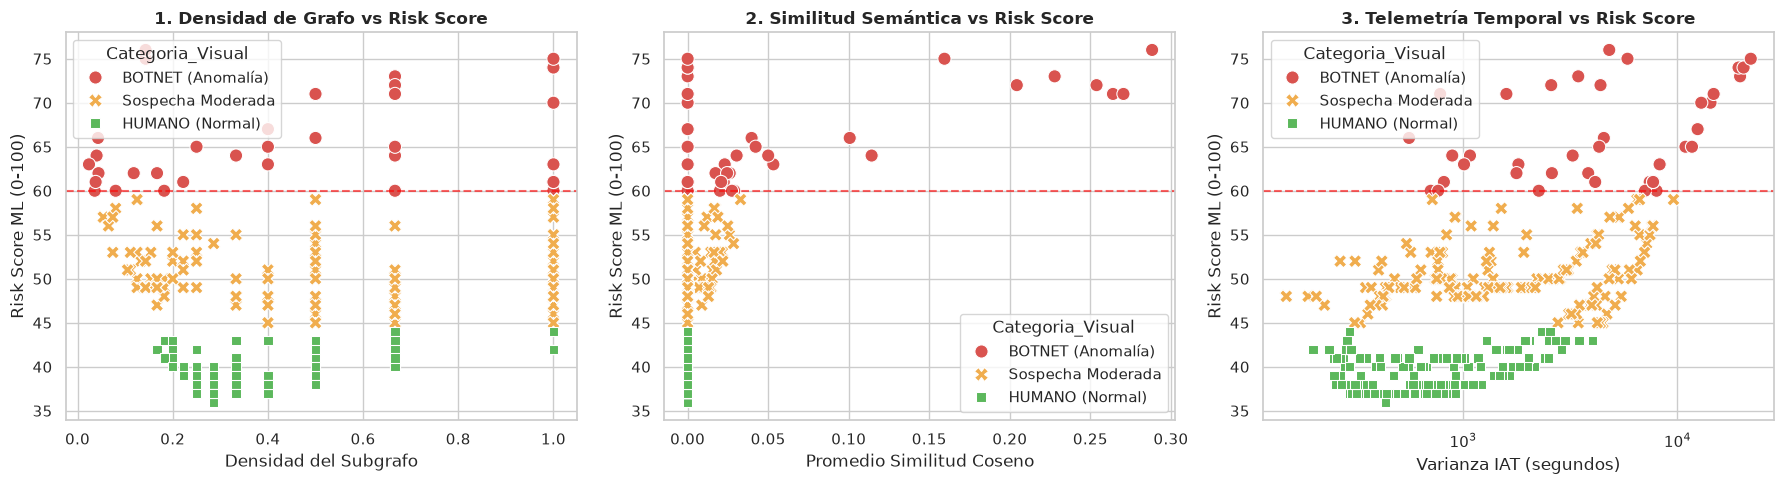

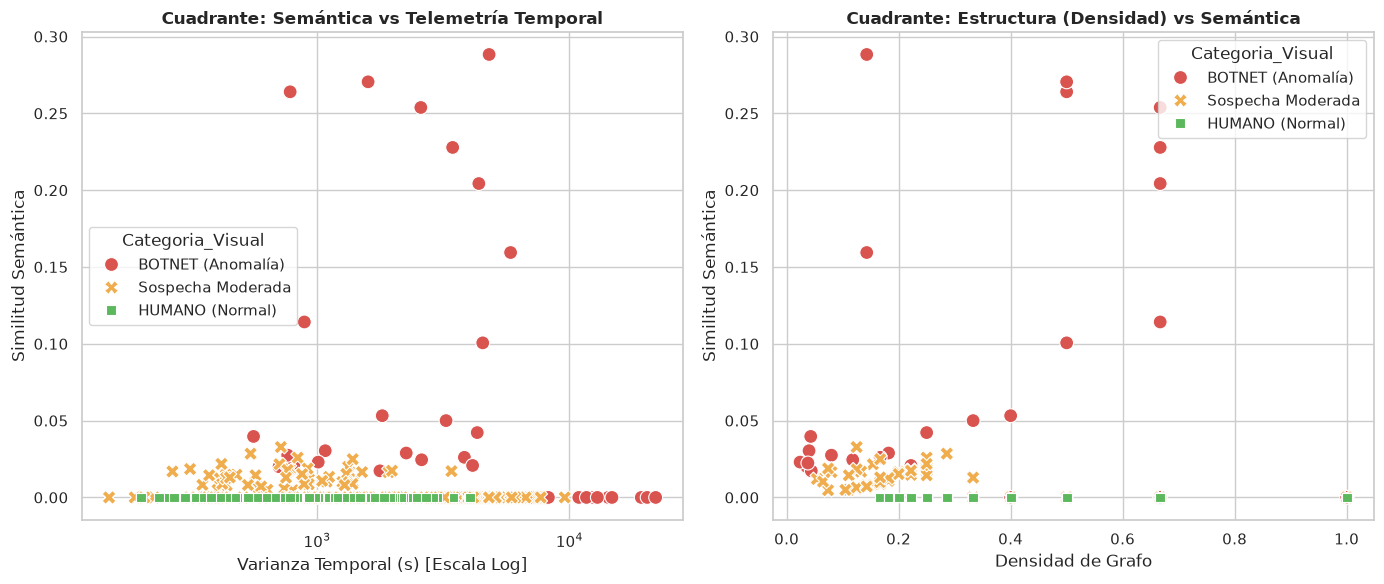


--- ANÁLISIS DE COMPLEMENTARIEDAD DE MODELOS (IF vs LOF) ---
Total comunidades analizadas: 844
Anomalías detectadas por Isolation Forest (Aislamiento global): 127
Anomalías detectadas por Local Outlier Factor (Densidad local): 118
Anomalías detectadas en la INTERSECCIÓN (Ambos modelos): 39
Anomalías detectadas SOLO por Isolation Forest: 88
Anomalías detectadas SOLO por LOF: 79
Porcentaje de solapamiento en la unión de anomalías: 18.93%


/home/adalisa/Documentos/proyectos_git/proyecto_botnet/venv_bot/lib/python3.12/site-packages/sklearn/neighbors/_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


In [18]:


# Se utiliza el DataFrame de resultados obtenido previamente (report_df o report_rows)
# Asumiendo que report_df contiene las columnas:
# 'Comunidad', 'Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)', 'Risk Score ML', 'Clasificación ML'

df_analysis = report_df.copy()

# Categorización en 3 niveles para visualización clara
def categorize_risk(score):
    if score >= 60:
        return 'BOTNET (Anomalía)'
    elif score >= 45:
        return 'Sospecha Moderada'
    else:
        return 'HUMANO (Normal)'

df_analysis['Categoria_Visual'] = df_analysis['Risk Score ML'].apply(categorize_risk)

# Muestreo representativo de la clase normal para evitar saturación visual en gráficos
df_bots = df_analysis[df_analysis['Categoria_Visual'] == 'BOTNET (Anomalía)']
df_susp = df_analysis[df_analysis['Categoria_Visual'] == 'Sospecha Moderada']
df_norm = df_analysis[df_analysis['Categoria_Visual'] == 'HUMANO (Normal)']

# Tomamos una muestra de hasta 200 normales si hay demasiadas
if len(df_norm) > 200:
    df_norm_sample = df_norm.sample(n=200, random_state=42)
else:
    df_norm_sample = df_norm

df_plot = pd.concat([df_bots, df_susp, df_norm_sample], ignore_index=True)

# Configuración del estilo de gráficos
sns.set_theme(style="whitegrid")
palette = {
    'BOTNET (Anomalía)': '#d9534f',    # Rojo
    'Sospecha Moderada': '#f0ad4e',    # Naranja/Amarillo
    'HUMANO (Normal)': '#5cb85c'       # Verde
}

# ==========================================
# FIGURA 1: CADA DIMENSIÓN VS RISK SCORE
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A) Densidad Grafo vs Risk Score
sns.scatterplot(
    data=df_plot, x='Densidad Grafo', y='Risk Score ML',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=90, ax=axes[0]
)
axes[0].set_title('1. Densidad de Grafo vs Risk Score', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Densidad del Subgrafo')
axes[0].set_ylabel('Risk Score ML (0-100)')
axes[0].axhline(60, color='red', linestyle='--', alpha=0.6, label='Umbral Botnet')

# B) Similitud Semántica vs Risk Score
sns.scatterplot(
    data=df_plot, x='Simil. Semántica', y='Risk Score ML',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=90, ax=axes[1]
)
axes[1].set_title('2. Similitud Semántica vs Risk Score', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Promedio Similitud Coseno')
axes[1].set_ylabel('Risk Score ML (0-100)')
axes[1].axhline(60, color='red', linestyle='--', alpha=0.6)

# C) Varianza Temporal vs Risk Score (Escala Log en X si los valores varían mucho)
sns.scatterplot(
    data=df_plot, x='Varianza Temp. (s)', y='Risk Score ML',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=90, ax=axes[2]
)
axes[2].set_title('3. Telemetría Temporal vs Risk Score', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Varianza IAT (segundos)')
axes[2].set_ylabel('Risk Score ML (0-100)')
axes[2].axhline(60, color='red', linestyle='--', alpha=0.6)
axes[2].set_xscale('log')

plt.tight_layout()
plt.show()

# ==========================================
# FIGURA 2: MATRIZ DE CUADRANTES 2D (DEMOSTRACIÓN MULTI-CAPA)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# A) Similitud vs Varianza Temporal
sns.scatterplot(
    data=df_plot, x='Varianza Temp. (s)', y='Simil. Semántica',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=100, ax=axes[0]
)
axes[0].set_title('Cuadrante: Semántica vs Telemetría Temporal', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Varianza Temporal (s) [Escala Log]')
axes[0].set_ylabel('Similitud Semántica')
axes[0].set_xscale('log')

# B) Densidad vs Similitud Semántica
sns.scatterplot(
    data=df_plot, x='Densidad Grafo', y='Simil. Semántica',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=100, ax=axes[1]
)
axes[1].set_title('Cuadrante: Estructura (Densidad) vs Semántica', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Densidad de Grafo')
axes[1].set_ylabel('Similitud Semántica')

plt.tight_layout()
plt.show()

# ==========================================
# EVALUACIÓN DE COMPLEMENTARIEDAD: IF vs LOF
# ==========================================
# Construimos la matriz de características X_real desde df_analysis
X_features = df_analysis[['Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)']].values

# 1. Isolation Forest (Anomalías globales / aislamiento)
if_model = IsolationForest(contamination=0.15, random_state=42)
if_preds = if_model.fit_predict(X_features)  # -1 anómalo, 1 normal

# 2. Local Outlier Factor (Anomalías locales / densidad relativa)
lof_model = LocalOutlierFactor(n_neighbors=35, contamination=0.15)
lof_preds = lof_model.fit_predict(X_features)  # -1 anómalo, 1 normal

# Análisis de conjuntos de detección
if_anomalies = set(np.where(if_preds == -1)[0])
lof_anomalies = set(np.where(lof_preds == -1)[0])

intersection = if_anomalies.intersection(lof_anomalies)
only_if = if_anomalies - lof_anomalies
only_lof = lof_anomalies - if_anomalies
union = if_anomalies.union(lof_anomalies)

pct_intersection = (len(intersection) / len(union) * 100) if union else 0

print("\n--- ANÁLISIS DE COMPLEMENTARIEDAD DE MODELOS (IF vs LOF) ---")
print(f"Total comunidades analizadas: {len(X_features)}")
print(f"Anomalías detectadas por Isolation Forest (Aislamiento global): {len(if_anomalies)}")
print(f"Anomalías detectadas por Local Outlier Factor (Densidad local): {len(lof_anomalies)}")
print(f"Anomalías detectadas en la INTERSECCIÓN (Ambos modelos): {len(intersection)}")
print(f"Anomalías detectadas SOLO por Isolation Forest: {len(only_if)}")
print(f"Anomalías detectadas SOLO por LOF: {len(only_lof)}")
print(f"Porcentaje de solapamiento en la unión de anomalías: {pct_intersection:.2f}%")